# MLOps Assignment 01 - End-to-End Heart Disease Classification

**Course:** AIMLCZG523

**Goal:** Build a reproducible heart-disease classification workflow with EDA, model comparison, MLflow experiment tracking, model packaging, API, tests, CI/CD, containerization, deployment configuration, monitoring evidence and documentation.

## How to run this notebook

- Run cells **from top to bottom**, one at a time.
- Do not skip cells that create variables or artifacts used later.
- Keep the notebook inside the repository so the relative project paths work correctly.


## 0. Configure project paths

Set a portable project root for local development or Jupyter. Keep the project under the repository/workspace directory and avoid machine-specific paths.


In [1]:
from pathlib import Path
import os, sys, platform, json, textwrap, subprocess, shutil, warnings
from datetime import datetime

# Portable project root: works when Jupyter starts in the repository root
# or in the notebooks/ directory.
PROJECT_DIR = Path.cwd().resolve()
if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent

# If Jupyter was opened from another directory, point this at the project root:
# PROJECT_DIR = Path.home() / "workspace" / "MLOps_Assignment_01"

DATA_RAW = PROJECT_DIR / "data" / "raw"
DATA_PROCESSED = PROJECT_DIR / "data" / "processed"
NOTEBOOKS_DIR = PROJECT_DIR / "notebooks"
SRC_DIR = PROJECT_DIR / "src"
TESTS_DIR = PROJECT_DIR / "tests"
ARTIFACTS_DIR = PROJECT_DIR / "artifacts"
DEPLOYMENT_DIR = PROJECT_DIR / "deployment"
SCREENSHOTS_DIR = PROJECT_DIR / "screenshots"
WORKFLOWS_DIR = PROJECT_DIR / ".github" / "workflows"

for folder in [
    DATA_RAW, DATA_PROCESSED, NOTEBOOKS_DIR, SRC_DIR, TESTS_DIR,
    ARTIFACTS_DIR, DEPLOYMENT_DIR, SCREENSHOTS_DIR, WORKFLOWS_DIR
]:
    folder.mkdir(parents=True, exist_ok=True)

print("Python version:", sys.version)
print("Project directory:", PROJECT_DIR)
print("Project directory exists:", PROJECT_DIR.exists())
print("Created project folders successfully.")


Python version: 3.14.7 (main, Aug  5 2026, 10:29:49) [Clang 21.0.0 (clang-2100.1.1.101)]
Project directory: /Users/rohittukaramdaddekar/Documents/Rohit/BITS/Sem3/MLOPS/Assignment_1/Git_Repo/mlops_assignment_01
Project directory exists: True
Created project folders successfully.


## 1. Install the development dependencies

Install the same packages used by the repository. If the environment already has them, this cell should finish quickly.


In [2]:
import subprocess
import sys

subprocess.check_call([
    sys.executable,
    "-m",
    "pip",
    "install",
    "-q",
    "-r",
    str(PROJECT_DIR / "requirements.txt"),
])


0

## 2. Verify packages

In [3]:
import importlib.metadata as metadata
for package in ["numpy", "pandas", "scikit-learn", "matplotlib", "seaborn",
                "ucimlrepo", "mlflow", "fastapi", "uvicorn", "httpx", "pytest", "ruff"]:
    try:
        print(f"{package}: {metadata.version(package)}")
    except metadata.PackageNotFoundError:
        print(f"{package}: NOT INSTALLED")

numpy: 2.5.4
pandas: 2.3.3
scikit-learn: 1.9.1
matplotlib: 3.11.2
seaborn: 0.13.2
ucimlrepo: 0.0.7
mlflow: 3.17.0
fastapi: 0.143.0
uvicorn: 0.54.0
httpx: 0.28.1
pytest: 8.4.2
ruff: 0.17.0


## 3. Acquire the UCI Heart Disease dataset

The dataset's target can be represented as values `0` through `4`: `0` indicates no disease and values above `0` indicate presence of disease. For a binary classification task, this notebook maps target `0` to `0` and targets `1–4` to `1`.

We will save the raw features and target to disk and inspect the schema. If `data/raw/heart_disease_uci_raw.csv` already exists it is reused; otherwise the data is downloaded with `ucimlrepo`. If the UCI endpoint is temporarily unavailable, retry this cell before changing the data source.

In [4]:
from ucimlrepo import fetch_ucirepo
import pandas as pd
import numpy as np

raw_path = DATA_RAW / "heart_disease_uci_raw.csv"
if raw_path.exists():
    # Reuse the cached download so the notebook also runs offline.
    cached = pd.read_csv(raw_path)
    X_raw = cached.drop(columns=[cached.columns[-1]])
    y_raw = cached[[cached.columns[-1]]]
    print("Loaded cached raw dataset from:", raw_path)
else:
    heart = fetch_ucirepo(id=45)
    X_raw = heart.data.features.copy()
    y_raw = heart.data.targets.copy()

print("Feature shape:", X_raw.shape)
print("Target shape:", y_raw.shape)
print("\nFeature columns:")
print(X_raw.columns.tolist())
print("\nTarget columns:")
print(y_raw.columns.tolist())
display(X_raw.head())
display(y_raw.head())

raw_df = X_raw.copy()
target_col = y_raw.columns[0]
raw_df[target_col] = y_raw[target_col].values
raw_df.to_csv(raw_path, index=False)
print("\nSaved raw dataset to:", raw_path)

Loaded cached raw dataset from: /Users/rohittukaramdaddekar/Documents/Rohit/BITS/Sem3/MLOPS/Assignment_1/Git_Repo/mlops_assignment_01/data/raw/heart_disease_uci_raw.csv
Feature shape: (303, 13)
Target shape: (303, 1)

Feature columns:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']

Target columns:
['num']


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0


,num
0,0
1,2
2,1
3,0
4,0



Saved raw dataset to: /Users/rohittukaramdaddekar/Documents/Rohit/BITS/Sem3/MLOPS/Assignment_1/Git_Repo/mlops_assignment_01/data/raw/heart_disease_uci_raw.csv


## 4. Data quality checks and cleaning

The UCI data can contain missing values marked as `?` or encoded as missing values. We convert those to `NaN`, coerce numeric-looking columns, and report missingness. Imputation and scaling will be fitted inside the model pipeline later, which avoids fitting preprocessing on the test set.

In [5]:
df = raw_df.copy()
df = df.replace(["?", "NA", "N/A", ""], np.nan)

for col in df.columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print("Shape:", df.shape)
print("\nMissing values per column:")
display(df.isna().sum().sort_values(ascending=False).to_frame("missing_count"))
print("\nDuplicate rows:", int(df.duplicated().sum()))
print("\nTarget distribution before binary mapping:")
display(df[target_col].value_counts(dropna=False).sort_index().to_frame("count"))

# Remove rows with missing target because a supervised target cannot be imputed reliably.
df = df.dropna(subset=[target_col]).copy()
df[target_col] = (df[target_col].astype(float) > 0).astype(int)

# Keep a clean copy; feature missing values are imputed within the sklearn pipeline.
clean_path = DATA_PROCESSED / "heart_disease_clean.csv"
df.to_csv(clean_path, index=False)

X = df.drop(columns=[target_col])
y = df[target_col].astype(int)
print("\nCleaned shape:", df.shape)
print("Binary target counts:")
display(y.value_counts().sort_index().rename(index={0: "no disease", 1: "disease"}).to_frame("count"))

Shape: (303, 14)

Missing values per column:


,missing_count
ca,4
thal,2
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0



Duplicate rows: 0

Target distribution before binary mapping:


,count
num,
0,164
1,55
2,36
3,35
4,13



Cleaned shape: (303, 14)
Binary target counts:


,count
num,
no disease,164
disease,139


## 5. Exploratory Data Analysis (EDA)

The following visualizations cover distributions, class balance, and correlations. Numeric conversion is applied above, so these plots should be compatible with the dataset columns.

,count,mean,std,min,25%,50%,75%,max
age,303.0,54.438944,9.038662,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.679868,0.467299,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.158416,0.960126,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.689769,17.599748,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.693069,51.776918,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.990099,0.994971,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.607261,22.875003,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2


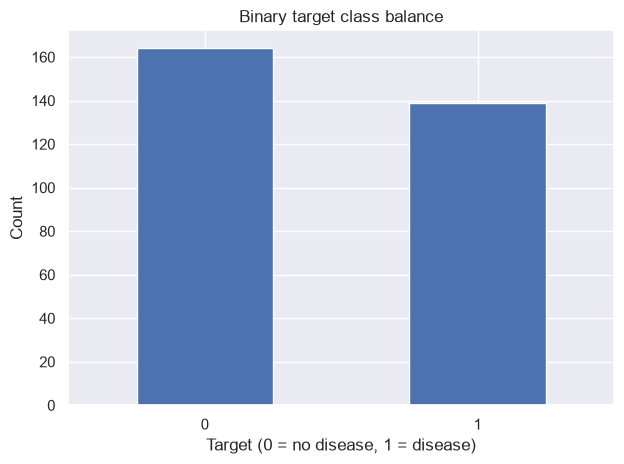

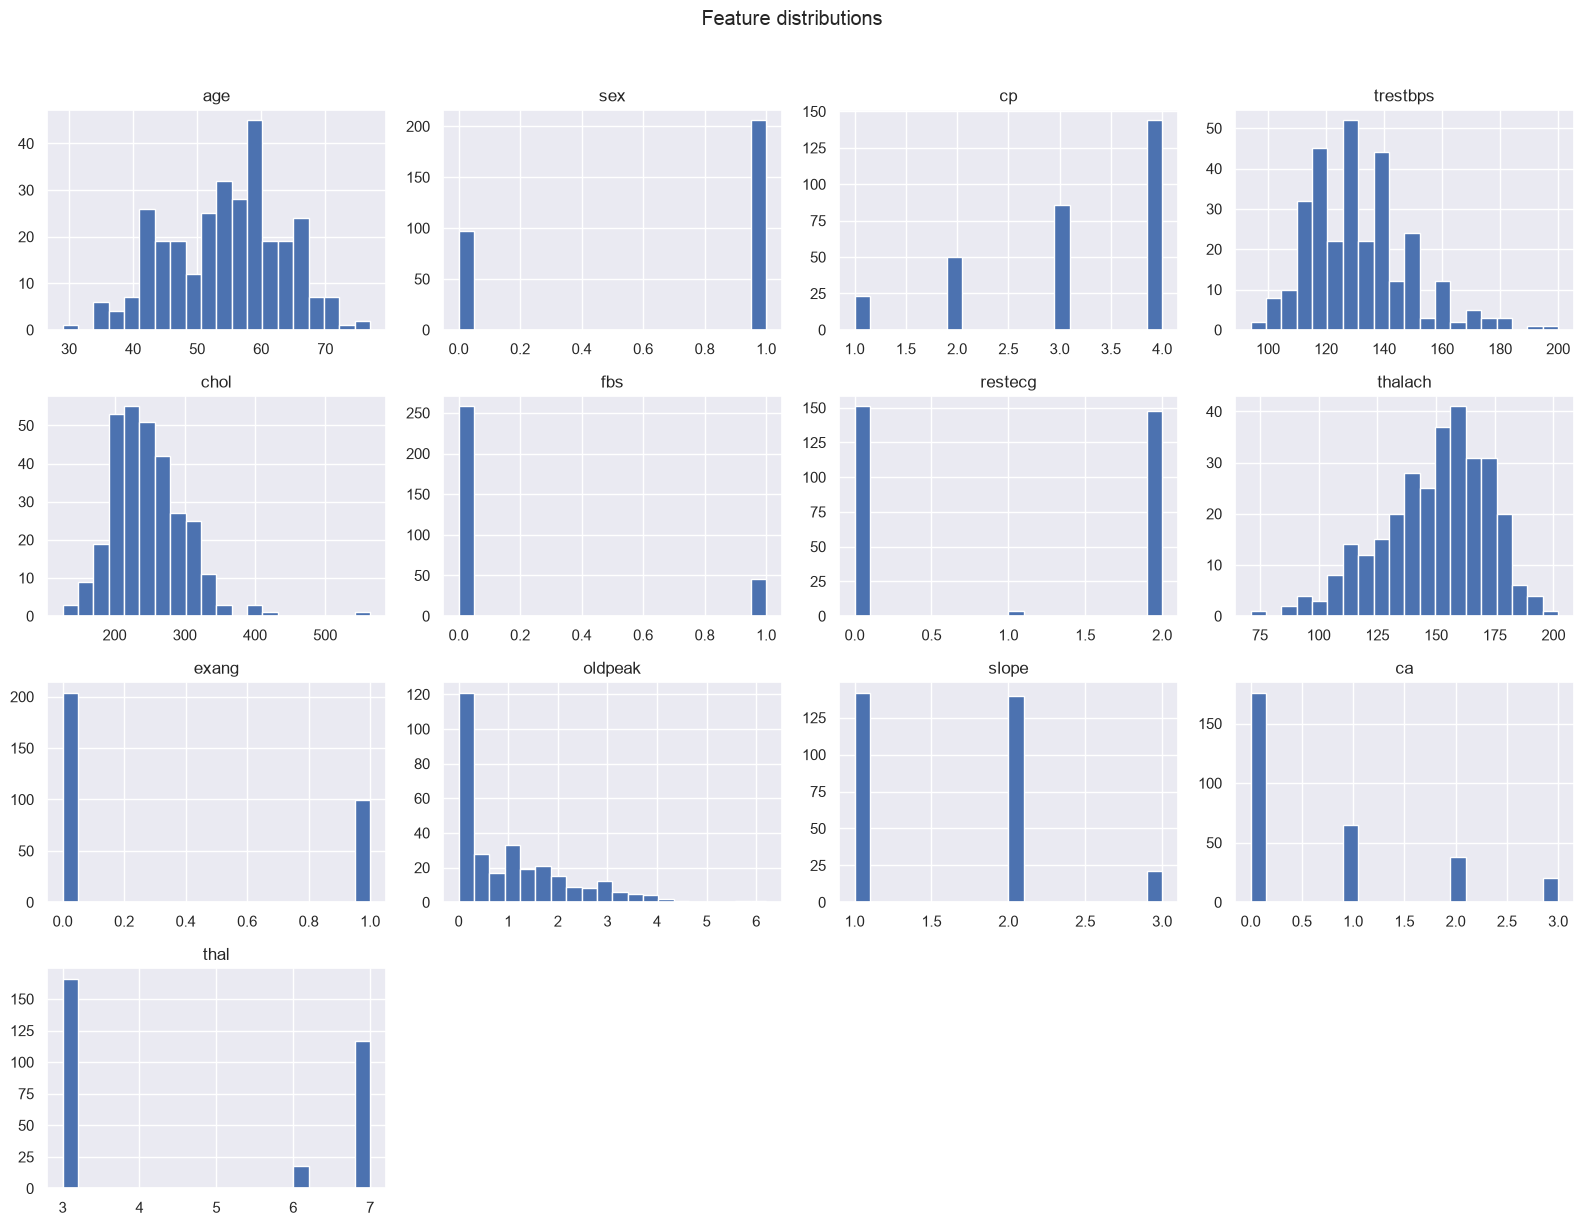

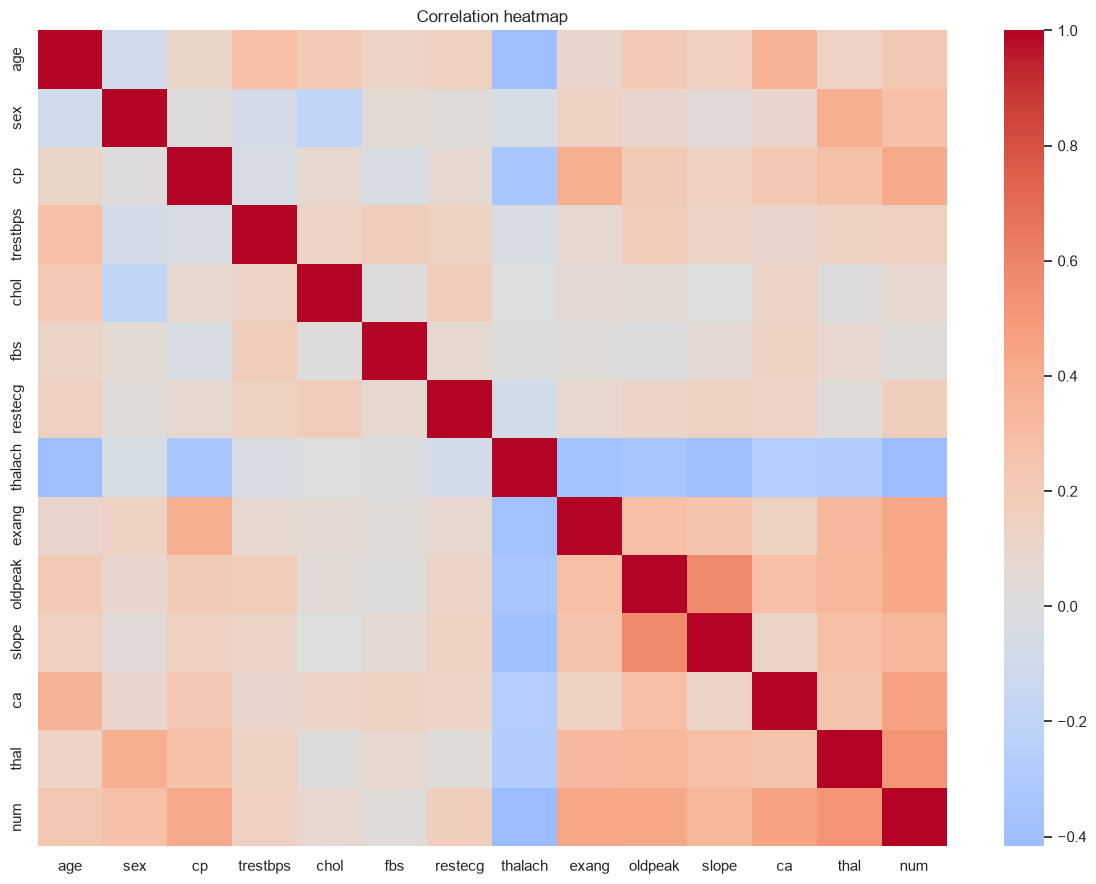

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme()
display(df.describe().T)

ax = y.value_counts().sort_index().plot(kind="bar", rot=0)
ax.set_title("Binary target class balance")
ax.set_xlabel("Target (0 = no disease, 1 = disease)")
ax.set_ylabel("Count")
plt.tight_layout()
plt.show()

df.drop(columns=[target_col]).hist(figsize=(16, 12), bins=20)
plt.suptitle("Feature distributions", y=1.02)
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 9))
sns.heatmap(df.corr(numeric_only=True), cmap="coolwarm", center=0, annot=False)
plt.title("Correlation heatmap")
plt.tight_layout()
plt.show()

## 6. Train/test split and preprocessing pipeline

We compare Logistic Regression and Random Forest. Both pipelines are built by `build_models` in `src/train.py`, so the notebook and the training script use exactly the same preprocessing. Numeric missing values are imputed with the median and Logistic Regression also scales them. The nominal features `cp`, `restecg`, `slope` and `thal` are integer codes with no numeric order, so they are imputed with the most frequent value and one-hot encoded. The split is stratified to preserve class proportions. Cross-validation and final evaluation are performed on training and held-out test data respectively.

In [7]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, ConfusionMatrixDisplay,
    RocCurveDisplay
)
import numpy as np

# Remove any columns that are completely missing, as median imputation cannot recover them.
all_missing = X.columns[X.isna().all()].tolist()
if all_missing:
    print("Dropping entirely missing columns:", all_missing)
    X = X.drop(columns=all_missing)

# Reuse the training script's pipelines so the notebook and src/train.py stay identical.
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))
from src.train import CATEGORICAL_FEATURES, build_models
%matplotlib inline
# src.train switches matplotlib to the headless Agg backend for CI; switch back so plots show here.

# Full ordered feature list (the API's feature contract); the name is kept for later cells.
numeric_features = X.columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

lr_pipeline, rf_pipeline = build_models(numeric_features)
models = {
    "logistic_regression": lr_pipeline,
    "random_forest": rf_pipeline,
}

print("Train shape:", X_train.shape, "Test shape:", X_test.shape)
print("Features:", numeric_features)
print("One-hot encoded:", [c for c in numeric_features if c in CATEGORICAL_FEATURES])
display(models["logistic_regression"])

Train shape: (242, 13) Test shape: (61, 13)
Features: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']
One-hot encoded: ['cp', 'restecg', 'slope', 'thal']


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, defau

## 7. Cross-validation and model comparison

We log accuracy, precision, recall, F1 and ROC-AUC where probability estimates are available. Recall and ROC-AUC are useful here because the classes are not exactly balanced, so accuracy alone would not be enough to compare models.


In [8]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

cv_results = {}
for name, pipeline in models.items():
    scores = cross_validate(
        pipeline, X_train, y_train, cv=cv, scoring=scoring,
        return_train_score=False, error_score="raise"
    )
    cv_results[name] = {
        metric: float(np.mean(scores[f"test_{metric}"]))
        for metric in scoring
    }

cv_df = pd.DataFrame(cv_results).T.sort_values("roc_auc", ascending=False)
display(cv_df)

,accuracy,precision,recall,f1,roc_auc
logistic_regression,0.846939,0.848378,0.818972,0.830775,0.906873
random_forest,0.801446,0.788520,0.782609,0.781539,0.897847


## 8. Hyperparameter tuning for Random Forest

This is a modest search suitable for a small dataset. We tune on the training split only. The held-out test split remains untouched until final evaluation.

In [9]:
rf_search = GridSearchCV(
    estimator=models["random_forest"],
    param_grid={
        "model__n_estimators": [200, 400],
        "model__max_depth": [None, 5, 10],
        "model__min_samples_leaf": [1, 2, 4]
    },
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1,
    refit=True
)
rf_search.fit(X_train, y_train)

best_rf = rf_search.best_estimator_
print("Best RF params:", rf_search.best_params_)
print("Best RF CV ROC-AUC:", round(rf_search.best_score_, 4))

# Refit logistic regression on training data for fair held-out comparison.
best_lr = models["logistic_regression"].fit(X_train, y_train)

Best RF params: {'model__max_depth': None, 'model__min_samples_leaf': 4, 'model__n_estimators': 200}
Best RF CV ROC-AUC: 0.9026


## 9. Held-out test evaluation and model selection

Select the final model using training cross-validation results, then evaluate it on the test set. We use ROC-AUC as the selection criterion when available; record the rationale in the final report rather than choosing a model only because it has the highest accuracy.

,model,accuracy,precision,recall,f1,roc_auc
0,logistic_regression,0.868852,0.81250,0.928571,0.866667,0.957792
1,random_forest_tuned,0.885246,0.83871,0.928571,0.881356,0.946970


Selected model: logistic_regression

Classification report:
              precision    recall  f1-score   support

           0       0.93      0.82      0.87        33
           1       0.81      0.93      0.87        28

    accuracy                           0.87        61
   macro avg       0.87      0.87      0.87        61
weighted avg       0.88      0.87      0.87        61



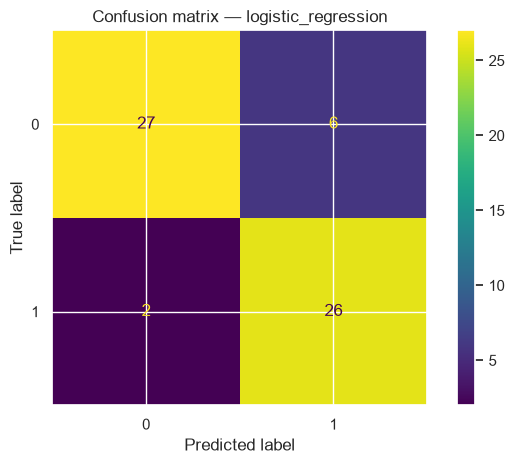

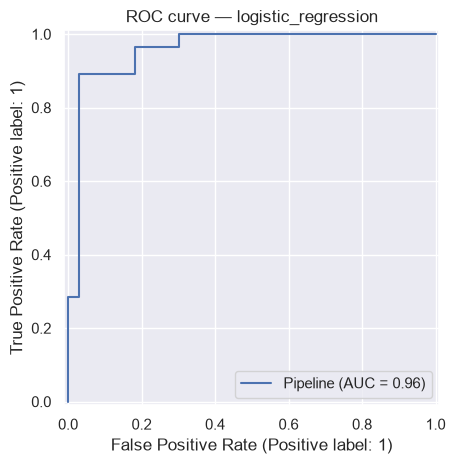

In [10]:
candidate_models = {
    "logistic_regression": best_lr,
    "random_forest_tuned": best_rf
}
evaluation_rows = []
for name, fitted_model in candidate_models.items():
    pred = fitted_model.predict(X_test)
    proba = fitted_model.predict_proba(X_test)[:, 1]
    evaluation_rows.append({
        "model": name,
        "accuracy": accuracy_score(y_test, pred),
        "precision": precision_score(y_test, pred, zero_division=0),
        "recall": recall_score(y_test, pred, zero_division=0),
        "f1": f1_score(y_test, pred, zero_division=0),
        "roc_auc": roc_auc_score(y_test, proba)
    })

evaluation_df = pd.DataFrame(evaluation_rows).sort_values("roc_auc", ascending=False)
display(evaluation_df)

# Select by training cross-validation ROC-AUC (not held-out test results).
cv_auc_by_candidate = {
    "logistic_regression": float(cv_df.loc["logistic_regression", "roc_auc"]),
    "random_forest_tuned": float(rf_search.best_score_),
}
best_name = max(cv_auc_by_candidate, key=cv_auc_by_candidate.get)
best_model = candidate_models[best_name]
print("Selected model:", best_name)
print("\nClassification report:")
print(classification_report(y_test, best_model.predict(X_test), zero_division=0))

ConfusionMatrixDisplay.from_estimator(best_model, X_test, y_test)
plt.title(f"Confusion matrix — {best_name}")
plt.tight_layout()
plt.show()

RocCurveDisplay.from_estimator(best_model, X_test, y_test)
plt.title(f"ROC curve — {best_name}")
plt.tight_layout()
plt.show()

## 10. MLflow experiment tracking

This section uses **MLflow for experiment tracking** with a SQLite backend. SQLite is only the tracking database backend; MLflow remains responsible for logging runs, parameters, metrics, models and artifacts.

The experiment will track both candidate models:
- Logistic Regression
- Tuned Random Forest

Each run records cross-validation ROC-AUC, held-out test metrics, model parameters and artifacts. Run this section only after model evaluation in Section 9 has completed successfully.

In [11]:
import mlflow
print("MLflow version:", mlflow.__version__)
print("Project directory:", PROJECT_DIR)

MLflow version: 3.17.0
Project directory: /Users/rohittukaramdaddekar/Documents/Rohit/BITS/Sem3/MLOPS/Assignment_1/Git_Repo/mlops_assignment_01


In [12]:
import mlflow
import mlflow.sklearn
from mlflow.models import infer_signature

# Persist MLflow tracking database and artifacts under the assignment folder.
MLFLOW_DB = PROJECT_DIR / "mlflow.db"
MLFLOW_ARTIFACTS = PROJECT_DIR / "mlartifacts"
MLFLOW_ARTIFACTS.mkdir(parents=True, exist_ok=True)

tracking_uri = f"sqlite:///{MLFLOW_DB.resolve().as_posix()}"
mlflow.set_tracking_uri(tracking_uri)

EXPERIMENT_NAME = "heart-disease-classification"
experiment = mlflow.get_experiment_by_name(EXPERIMENT_NAME)

if experiment is None:
    experiment_id = mlflow.create_experiment(
        EXPERIMENT_NAME,
        artifact_location=MLFLOW_ARTIFACTS.resolve().as_uri()
    )
else:
    experiment_id = experiment.experiment_id
    expected_artifact_root = MLFLOW_ARTIFACTS.resolve().as_uri()
    if not experiment.artifact_location.startswith(expected_artifact_root):
        print(
            "WARNING: Existing experiment artifact location is:",
            experiment.artifact_location,
            "\nExisting experiments keep their original artifact location."
        )

mlflow.set_experiment(EXPERIMENT_NAME)

print("MLflow version:", mlflow.__version__)
print("Tracking URI:", mlflow.get_tracking_uri())
print("Experiment:", EXPERIMENT_NAME)
print("Experiment ID:", experiment_id)
print("Artifact directory for newly created experiment:", MLFLOW_ARTIFACTS)

MLflow version: 3.17.0
Tracking URI: sqlite:////Users/rohittukaramdaddekar/Documents/Rohit/BITS/Sem3/MLOPS/Assignment_1/Git_Repo/mlops_assignment_01/mlflow.db
Experiment: heart-disease-classification
Experiment ID: 1
Artifact directory for newly created experiment: /Users/rohittukaramdaddekar/Documents/Rohit/BITS/Sem3/MLOPS/Assignment_1/Git_Repo/mlops_assignment_01/mlartifacts


In [13]:

# Save comparison tables first
cv_csv = ARTIFACTS_DIR / "cross_validation_results.csv"
eval_csv = ARTIFACTS_DIR / "test_evaluation_results.csv"

cv_df.to_csv(cv_csv, index=True)
evaluation_df.to_csv(eval_csv, index=False)

# Match tuned model names to the cross-validation table
cv_name_map = {
    "logistic_regression": "logistic_regression",
    "random_forest_tuned": "random_forest",
}

logged_run_ids = []

for model_name, fitted_model in candidate_models.items():

    row = evaluation_df.loc[
        evaluation_df["model"] == model_name
    ].iloc[0]

    cv_name = cv_name_map[model_name]
    cv_roc_auc = float(cv_df.loc[cv_name, "roc_auc"])

    with mlflow.start_run(run_name=model_name) as run:
        logged_run_ids.append(run.info.run_id)

        mlflow.set_tag("assignment", "MLOps Assignment 01")
        mlflow.set_tag(
            "dataset", "UCI Heart Disease, repository ID 45"
        )
        mlflow.set_tag(
            "selected_model", str(model_name == best_name)
        )

        mlflow.log_params({
            "model_name": model_name,
            "dataset": "UCI Heart Disease (id=45)",
            "target_mapping": "0 -> 0; values > 0 -> 1",
            "random_state": 42,
            "test_size": 0.2,
            "cross_validation_folds": 5,
        })

        mlflow.log_metric("cv_roc_auc_mean", cv_roc_auc)

        if model_name == "random_forest_tuned":
            mlflow.log_params({
                key: value
                for key, value in rf_search.best_params_.items()
            })

        for metric in [
            "accuracy", "precision", "recall", "f1", "roc_auc"
        ]:
            mlflow.log_metric(
                f"test_{metric}", float(row[metric])
            )

        mlflow.log_artifact(
            str(cv_csv), artifact_path="evaluation"
        )
        mlflow.log_artifact(
            str(eval_csv), artifact_path="evaluation"
        )

        # Use float inputs in the model signature to support
        # numeric values that may contain missing data.
        sample_input = X_train.head(3).astype("float64")
        sample_output = fitted_model.predict(sample_input)

        signature = infer_signature(
            sample_input,
            sample_output
        )

        mlflow.sklearn.log_model(
            sk_model=fitted_model,
            name="model",
            input_example=sample_input,
            signature=signature,
            serialization_format="pickle",
        )

        print(
            f"Logged {model_name}; run_id={run.info.run_id}"
        )

print("\nMLflow experiment runs logged successfully.")
print("Tracking URI:", mlflow.get_tracking_uri())
print("Logged run IDs:", logged_run_ids)


2026/10/13 12:27:32 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


2026/10/13 12:27:34 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Logged logistic_regression; run_id=4967169c8327496abf1cbeac6b24fcfe


Logged random_forest_tuned; run_id=5c9d40c9739745428592ae41965e8827

MLflow experiment runs logged successfully.
Tracking URI: sqlite:////Users/rohittukaramdaddekar/Documents/Rohit/BITS/Sem3/MLOPS/Assignment_1/Git_Repo/mlops_assignment_01/mlflow.db
Logged run IDs: ['4967169c8327496abf1cbeac6b24fcfe', '5c9d40c9739745428592ae41965e8827']


In [14]:
experiment = mlflow.get_experiment_by_name(
    "heart-disease-classification"
)

runs = mlflow.search_runs(
    experiment_ids=[experiment.experiment_id]
)

print("Total tracked runs:", len(runs))
display(runs[[
    "tags.mlflow.runName",
    "status",
    "metrics.cv_roc_auc_mean",
    "metrics.test_accuracy",
    "metrics.test_recall",
    "metrics.test_roc_auc",
]])

Total tracked runs: 4


,tags.mlflow.runName,status,metrics.cv_roc_auc_mean,metrics.test_accuracy,metrics.test_recall,metrics.test_roc_auc
0,random_forest_tuned,FINISHED,0.897847,0.885246,0.928571,0.946970
1,logistic_regression,FINISHED,0.906873,0.868852,0.928571,0.957792
2,random_forest_tuned,FINISHED,0.902582,0.885246,0.928571,0.946970
3,logistic_regression,FINISHED,0.906873,0.868852,0.928571,0.957792


## 10.1 Verify tracked MLflow runs

This cell should show completed MLflow runs for Logistic Regression and tuned Random Forest. If you previously ran a smoke test, it may also appear in the experiment history.

In [15]:
experiment = mlflow.get_experiment_by_name(EXPERIMENT_NAME)
runs = mlflow.search_runs(
    experiment_ids=[experiment.experiment_id],
    order_by=["attributes.start_time DESC"]
)

print("Experiment:", experiment.name)
print("Total tracked runs:", len(runs))

display_columns = [
    "run_id", "tags.mlflow.runName", "status",
    "metrics.cv_roc_auc_mean", "metrics.test_accuracy",
    "metrics.test_precision", "metrics.test_recall",
    "metrics.test_f1", "metrics.test_roc_auc"
]
available_columns = [column for column in display_columns if column in runs.columns]
display(runs[available_columns])

Experiment: heart-disease-classification
Total tracked runs: 4


,run_id,tags.mlflow.runName,status,metrics.cv_roc_auc_mean,metrics.test_accuracy,metrics.test_precision,metrics.test_recall,metrics.test_f1,metrics.test_roc_auc
0,5c9d40c9739745428592ae41965e8827,random_forest_tuned,FINISHED,0.897847,0.885246,0.83871,0.928571,0.881356,0.946970
1,4967169c8327496abf1cbeac6b24fcfe,logistic_regression,FINISHED,0.906873,0.868852,0.81250,0.928571,0.866667,0.957792
2,ee63727bdb984140956fb2c2e813d82c,random_forest_tuned,FINISHED,0.902582,0.885246,0.83871,0.928571,0.881356,0.946970
3,47dc9560cbf041ae9c64a36dfa11e827,logistic_regression,FINISHED,0.906873,0.868852,0.81250,0.928571,0.866667,0.957792


## 11. Save the final model and feature contract

The saved artifact includes preprocessing and the estimator in one scikit-learn pipeline. Keep the ordered feature list to validate incoming API payloads. Pickle/joblib artifacts should only be loaded from trusted sources.

In [16]:
import joblib

MODEL_PATH = ARTIFACTS_DIR / "heart_disease_pipeline.joblib"
FEATURES_PATH = ARTIFACTS_DIR / "feature_columns.json"
METRICS_PATH = ARTIFACTS_DIR / "final_metrics.json"

joblib.dump(best_model, MODEL_PATH)
FEATURES_PATH.write_text(json.dumps(numeric_features, indent=2))
final_row = evaluation_df[evaluation_df["model"] == best_name].iloc[0].to_dict()
final_row["selected_model"] = best_name
final_row["feature_columns"] = numeric_features
final_row["best_random_forest_params"] = rf_search.best_params_
METRICS_PATH.write_text(json.dumps(final_row, indent=2, default=float))

print("Saved model:", MODEL_PATH)
print("Saved features:", FEATURES_PATH)
print("Saved metrics:", METRICS_PATH)

Saved model: /Users/rohittukaramdaddekar/Documents/Rohit/BITS/Sem3/MLOPS/Assignment_1/Git_Repo/mlops_assignment_01/artifacts/heart_disease_pipeline.joblib
Saved features: /Users/rohittukaramdaddekar/Documents/Rohit/BITS/Sem3/MLOPS/Assignment_1/Git_Repo/mlops_assignment_01/artifacts/feature_columns.json
Saved metrics: /Users/rohittukaramdaddekar/Documents/Rohit/BITS/Sem3/MLOPS/Assignment_1/Git_Repo/mlops_assignment_01/artifacts/final_metrics.json


In [17]:

from pathlib import Path
import joblib
import numpy as np

# Use the portable project path defined in setup cell 0.

FINAL_MODEL_PATH = (
    PROJECT_DIR / "artifacts" / "heart_disease_pipeline.joblib"
)

# Check that the saved file exists
assert FINAL_MODEL_PATH.exists(), (
    f"Model file not found: {FINAL_MODEL_PATH}"
)

# Load the saved model
loaded_model = joblib.load(FINAL_MODEL_PATH)

# Test predictions on held-out test data
sample = X_test.head(5)
predictions = loaded_model.predict(sample)
probabilities = loaded_model.predict_proba(sample)[:, 1]

print("Loaded model:", type(loaded_model).__name__)
print("Model path:", FINAL_MODEL_PATH)
print("Predictions:", predictions)
print("Positive-class probabilities:", np.round(probabilities, 4))

# Validate the output
assert len(predictions) == len(sample)
assert set(predictions).issubset({0, 1})
assert np.all((probabilities >= 0) & (probabilities <= 1))

print("\nModel save and reload verification passed.")


Loaded model: Pipeline
Model path: /Users/rohittukaramdaddekar/Documents/Rohit/BITS/Sem3/MLOPS/Assignment_1/Git_Repo/mlops_assignment_01/artifacts/heart_disease_pipeline.joblib
Predictions: [0 1 0 0 0]
Positive-class probabilities: [0.2554 0.6149 0.025  0.042  0.3569]

Model save and reload verification passed.


## 12. Review reusable source code and API

The repository source files are kept as normal `.py` files instead of being generated from the notebook. This avoids overwriting the final API or tests when the notebook is rerun. The next cell checks that the API and prediction helper exist and shows the main files used for serving.


In [18]:
from pathlib import Path

source_files = [
    SRC_DIR / "__init__.py",
    SRC_DIR / "predict.py",
    SRC_DIR / "api.py",
]
for file_path in source_files:
    assert file_path.exists(), f"Missing source file: {file_path}"
    print(f"\n--- {file_path.relative_to(PROJECT_DIR)} ---")
    print(file_path.read_text()[:3000])



--- src/__init__.py ---
"""Heart Disease MLOps assignment package."""


--- src/predict.py ---
"""Prediction helper used by the API and quick local checks."""
from __future__ import annotations

import json
from pathlib import Path

import joblib
import pandas as pd
from sklearn.pipeline import Pipeline

ROOT = Path(__file__).resolve().parents[1]
ARTIFACTS = ROOT / "artifacts"
MODEL_PATH = ARTIFACTS / "heart_disease_pipeline.joblib"
FEATURES_PATH = ARTIFACTS / "feature_columns.json"


def load_model() -> tuple[Pipeline, list[str]]:
    """Load the trained sklearn pipeline and its expected feature order."""
    if not MODEL_PATH.exists() or not FEATURES_PATH.exists():
        raise FileNotFoundError(
            "Model artifacts are missing. Run `python -m src.train` first."
        )
    return joblib.load(MODEL_PATH), json.loads(FEATURES_PATH.read_text())


def predict(features: dict[str, float]) -> dict:
    """Run one prediction after checking that feature names match training."""


## 13. Review unit tests

The tests cover data cleaning (`test_data.py`), model pipelines including one-hot encoding (`test_model.py`), and the API (`test_api.py`). They use the saved model artifact, so run the training section before running the tests.


In [19]:
for name in ["test_data.py", "test_model.py", "test_api.py"]:
    test_file = TESTS_DIR / name
    assert test_file.exists(), f"Missing test file: {test_file}"
    print(f"\n--- tests/{name} ---")
    print(test_file.read_text())



--- tests/test_data.py ---
"""Unit tests for the data cleaning step in src/train.py."""
import numpy as np
import pandas as pd

from src.train import clean_dataframe, split_features_target


def make_raw():
    return pd.DataFrame({
        "age": [63, 37, "?", 56],
        "chol": [233, "NA", 204, 236],
        "ca": [0, 1, 2, np.nan],
        "num": [0, 2, 4, np.nan],
    })


def test_missing_markers_become_nan_and_columns_are_numeric():
    df = clean_dataframe(make_raw())
    assert df["age"].isna().sum() == 1
    assert df["chol"].isna().sum() == 1
    assert all(pd.api.types.is_numeric_dtype(df[c]) for c in df.columns)


def test_rows_without_target_are_dropped():
    df = clean_dataframe(make_raw())
    assert len(df) == 3


def test_target_is_mapped_to_binary():
    df = clean_dataframe(make_raw())
    assert df["num"].tolist() == [0, 1, 1]
    assert set(df["num"].unique()) <= {0, 1}


def test_unnamed_target_column_is_renamed():
    raw = make_raw().rename(columns={"num": "

## 14. Review reproducible dependency file and project configuration

The dependency file is maintained in the repository. It is checked here so the notebook record matches the files submitted for the assignment.


In [20]:
requirements_path = PROJECT_DIR / "requirements.txt"
gitignore_path = PROJECT_DIR / ".gitignore"
assert requirements_path.exists(), "requirements.txt is missing"
assert gitignore_path.exists(), ".gitignore is missing"

print("--- requirements.txt ---")
print(requirements_path.read_text())
print("--- .gitignore ---")
print(gitignore_path.read_text())


--- requirements.txt ---
numpy>=1.26,<3
pandas>=2.1,<3
scikit-learn==1.9.1
matplotlib>=3.8,<4
seaborn>=0.13,<1
ucimlrepo>=0.0.7,<1
mlflow>=3.0,<4
joblib>=1.3,<2
fastapi>=0.110,<1
uvicorn[standard]>=0.29,<1
prometheus-client>=0.20,<1
pydantic>=2.6,<3
httpx>=0.27,<1
pytest>=8,<9
ruff>=0.5,<1

--- .gitignore ---
# Python
__pycache__/
*.py[cod]
.venv/
venv/
.pytest_cache/
.ruff_cache/
.ipynb_checkpoints/

# MLflow tracking data (regenerated by `python -m src.train`)
mlflow.db
mlruns/
mlartifacts/

# CI and local run outputs
training.log
test-results.xml

# OS and editor files
.DS_Store
Thumbs.db
.vscode/
.idea/

# Secrets
.env



## 15. Review Dockerfile and GitHub Actions CI workflow

The CI workflow installs dependencies, trains the model artifacts, runs linting checks, and executes tests. These files are shown here as submission evidence rather than regenerated from the notebook.


In [21]:
dockerfile_path = PROJECT_DIR / "Dockerfile"
workflow_path = WORKFLOWS_DIR / "ci.yml"
assert dockerfile_path.exists(), "Dockerfile is missing"
assert workflow_path.exists(), "GitHub Actions workflow is missing"

print("--- Dockerfile ---")
print(dockerfile_path.read_text())
print("--- .github/workflows/ci.yml ---")
print(workflow_path.read_text())


--- Dockerfile ---
FROM python:3.12-slim
WORKDIR /app
ENV PYTHONDONTWRITEBYTECODE=1 PYTHONUNBUFFERED=1
COPY requirements.txt .
RUN pip install --no-cache-dir -r requirements.txt
COPY src ./src
COPY artifacts ./artifacts
EXPOSE 8000
HEALTHCHECK --interval=30s --timeout=5s --start-period=10s \
  CMD python -c "import urllib.request,sys; sys.exit(0 if urllib.request.urlopen('http://localhost:8000/health').status == 200 else 1)"
CMD ["uvicorn", "src.api:app", "--host", "0.0.0.0", "--port", "8000"]

--- .github/workflows/ci.yml ---
name: mlops-ci  ##

on:
  push:
  pull_request:
  workflow_dispatch:

jobs:
  test:
    name: Lint, train and test
    runs-on: ubuntu-latest

    steps:
      - name: Checkout repository
        uses: actions/checkout@v4

      - name: Set up Python
        uses: actions/setup-python@v5
        with:
          python-version: "3.12"
          cache: pip

      - name: Install dependencies
        run: |
          python -m pip install --upgrade pip
          pip

## 16. Review Kubernetes deployment manifest

The manifest can be used for a local Kubernetes run. If pushing to a registry, update the image name before applying it.


In [22]:
k8s_path = DEPLOYMENT_DIR / "kubernetes.yaml"
assert k8s_path.exists(), "Kubernetes manifest is missing"
print(k8s_path.read_text())


# Heart Disease API on Kubernetes (Docker Desktop or Minikube).
# Apply with: kubectl apply -f deployment/kubernetes.yaml
apiVersion: apps/v1
kind: Deployment
metadata:
  name: heart-disease-api
  labels:
    app: heart-disease-api
spec:
  replicas: 2
  selector:
    matchLabels:
      app: heart-disease-api
  template:
    metadata:
      labels:
        app: heart-disease-api
      annotations:
        # Lets a cluster Prometheus discover and scrape /metrics.
        prometheus.io/scrape: "true"
        prometheus.io/port: "8000"
        prometheus.io/path: "/metrics/"
    spec:
      containers:
        - name: api
          image: heart-disease-api:latest
          imagePullPolicy: IfNotPresent
          ports:
            - containerPort: 8000
          resources:
            requests:
              cpu: 100m
              memory: 256Mi
            limits:
              cpu: 500m
              memory: 512Mi
          readinessProbe:
            httpGet:
              path: /health

## 17. Review README/report notes

The repository README contains setup, training, API, Docker, Kubernetes, and result notes. The final report should add screenshots and verification evidence.


In [23]:
readme_path = PROJECT_DIR / "README.md"
assert readme_path.exists(), "README.md is missing"
print(readme_path.read_text())


# MLOps Assignment 01 — Heart Disease Classification

## Objective
Build a reproducible binary classifier for the UCI Heart Disease dataset, track experiments with MLflow, package inference behind a FastAPI service, test the service, and provide container/CI/deployment configuration...

## Dataset and target
The project uses UCI Heart Disease repository ID 45. Target values are mapped as `0 -> no disease` and values greater than `0 -> disease present`. The dataset is downloaded by `ucimlrepo` when a cached `data/raw/heart_disease_uci_raw.csv` is not present.

**Step-by-step execution guide (with the screenshot list): [docs/RUNBOOK.md](docs/RUNBOOK.md).** Report outline, architecture diagram and video plan: [docs/REPORT_GUIDE.md](docs/REPORT_GUIDE.md).

## Submission links
- Repository: https://github.com/2025ae05519/mlops_assignment_01
- Report: `report/` (add the final PDF/DOCX here)
- Video: _add link_
- API access: local only; see "Run API", "Docker" and "Kubernetes" below.

## Proj

## 18. Run unit tests and API smoke checks

This starts a local test client; it does not need a publicly exposed server. If the tests fail, inspect the error output and fix that before continuing. Lint warnings should also be addressed before pushing the repository.

In [24]:
# Ensure project root is importable
import sys
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

result = subprocess.run(
    [sys.executable, "-m", "pytest", "-q", str(TESTS_DIR)],
    cwd=str(PROJECT_DIR),
    text=True,
    capture_output=True
)
print(result.stdout)
print(result.stderr)
print("pytest exit code:", result.returncode)
if result.returncode != 0:
    raise RuntimeError("Tests failed. Review the output before continuing.")

................                                                         [100%]
=============================== warnings summary ===============================
.venv/lib/python3.14/site-packages/fastapi/testclient.py:1
  /Users/rohittukaramdaddekar/Documents/Rohit/BITS/Sem3/MLOPS/Assignment_1/Git_Repo/mlops_assignment_01/.venv/lib/python3.14/site-packages/fastapi/testclient.py:1: StarletteDeprecationWarning: Using `httpx` with `starlette.testclient` is deprecated; install `httpx2` instead.
    from starlette.testclient import TestClient as TestClient  # noqa

tests/test_data.py::test_missing_markers_become_nan_and_columns_are_numeric
tests/test_data.py::test_rows_without_target_are_dropped
tests/test_data.py::test_target_is_mapped_to_binary
tests/test_data.py::test_unnamed_target_column_is_renamed
tests/test_data.py::test_split_drops_columns_that_are_entirely_missing
  /Users/rohittukaramdaddekar/Documents/Rohit/BITS/Sem3/MLOPS/Assignment_1/Git_Repo/mlops_assignment_01/src/train.py:76